<a href="https://colab.research.google.com/github/sonammaan222-source/House_price_EDA/blob/main/House_price_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import Libraries and Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
df = pd.read_csv("train.csv")
print("Dataset Shape:", df.shape)
display(df.head())
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': (missing / len(df)) * 100
})
display(missing_df)

Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [ ]:
#Classify Variables
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(
        df[col],
        categories=order,
        ordered=True
    )

variable_summary = []

for col in df.columns:
    if col == "OverallQual":
        variable_type = "Ordinal"
    elif col in ordinal_map:
        variable_type = "Ordinal"
    elif col in numeric_cols:
        variable_type = "Numerical"
    else:
        variable_type = "Categorical"

    variable_summary.append({
        "Column": col,
        "Type": variable_type,
        "Unique Values": df[col].nunique(),
        "Example Values": df[col].dropna().unique()[:5].tolist()
    })

variable_summary = pd.DataFrame(variable_summary)

display(variable_summary)

In [2]:
#Descriptive Statistics
print("Numerical Descriptive Statistics")
display(df.describe())

columns = ["SalePrice", "GrLivArea", "LotArea"]

statistics_summary = []

for col in columns:
    data = df[col].dropna()

    statistics_summary.append({
        "Feature": col,
        "Mean": data.mean(),
        "Median": data.median(),
        "Mode": data.mode()[0],
        "Standard Deviation": data.std(),
        "Variance": data.var(),
        "Range": data.max() - data.min(),
        "Q1": data.quantile(0.25),
        "Q3": data.quantile(0.75),
        "IQR": data.quantile(0.75) - data.quantile(0.25),
        "Skewness": data.skew(),
        "Kurtosis": data.kurtosis()
    })

display(pd.DataFrame(statistics_summary))

print("\nCategorical Feature Frequencies")

for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n{col}")
    display(df[col].value_counts())
    print("Mode:", df[col].mode()[0])

print("\nSalePrice Distribution Interpretation")

if df["SalePrice"].mean() > df["SalePrice"].median():
    print("SalePrice is right-skewed because mean is greater than median.")
elif df["SalePrice"].mean() < df["SalePrice"].median():
    print("SalePrice is left-skewed because mean is less than median.")
else:
    print("SalePrice is approximately symmetric.")

Numerical Descriptive Statistics


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


,Feature,Mean,Median,Mode,Standard Deviation,Variance,Range,Q1,Q3,IQR,Skewness,Kurtosis
0,SalePrice,180921.195890,163000.0,140000,79442.502883,6.311111e+09,720100,129975.0,214000.00,84025.00,1.882876,6.536282
1,GrLivArea,1515.463699,1464.0,864,525.480383,2.761296e+05,5308,1129.5,1776.75,647.25,1.366560,4.895121
2,LotArea,10516.828082,9478.5,7200,9981.264932,9.962565e+07,213945,7553.5,11601.50,4048.00,12.207688,203.243271



Categorical Feature Frequencies

Neighborhood


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


Mode: NAmes

HouseStyle


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


Mode: 1Story

SalePrice Distribution Interpretation
SalePrice is right-skewed because mean is greater than median.


In [4]:
#Data Cleaning and Quality Checks
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

categorical_cols = df.select_dtypes(include="object").columns.tolist()

for col in categorical_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

absence_columns = [
    "PoolQC", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual",
    "GarageCond", "BsmtQual", "BsmtCond",
    "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType", "MiscFeature"
]

for col in absence_columns:
    if col in df.columns:
        df[col] = df[col].fillna("None")

if "LotFrontage" in df.columns:
    df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
        lambda x: x.fillna(x.median())
    )

numeric_missing = df.select_dtypes(include=np.number).columns[
    df.select_dtypes(include=np.number).isnull().any()
]

for col in numeric_missing:
    df[col] = df[col].fillna(df[col].median())

categorical_missing = df.select_dtypes(include="object").columns[
    df.select_dtypes(include="object").isnull().any()
]

for col in categorical_missing:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Cleaning:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nFinal Dataset Shape:", df.shape)

print("\nChecking Impossible Values:")

print("YearBuilt greater than YrSold:",
      (df["YearBuilt"] > df["YrSold"]).sum())

area_cols = [
    "LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"
]

for col in area_cols:
    print(f"Negative values in {col}:", (df[col] < 0).sum())

Duplicate Rows: 0
Shape After Removing Duplicates: (1460, 81)
Missing Values After Cleaning:


,0



Final Dataset Shape: (1460, 81)

Checking Impossible Values:
YearBuilt greater than YrSold: 0
Negative values in LotArea: 0
Negative values in GrLivArea: 0
Negative values in TotalBsmtSF: 0
Negative values in GarageArea: 0


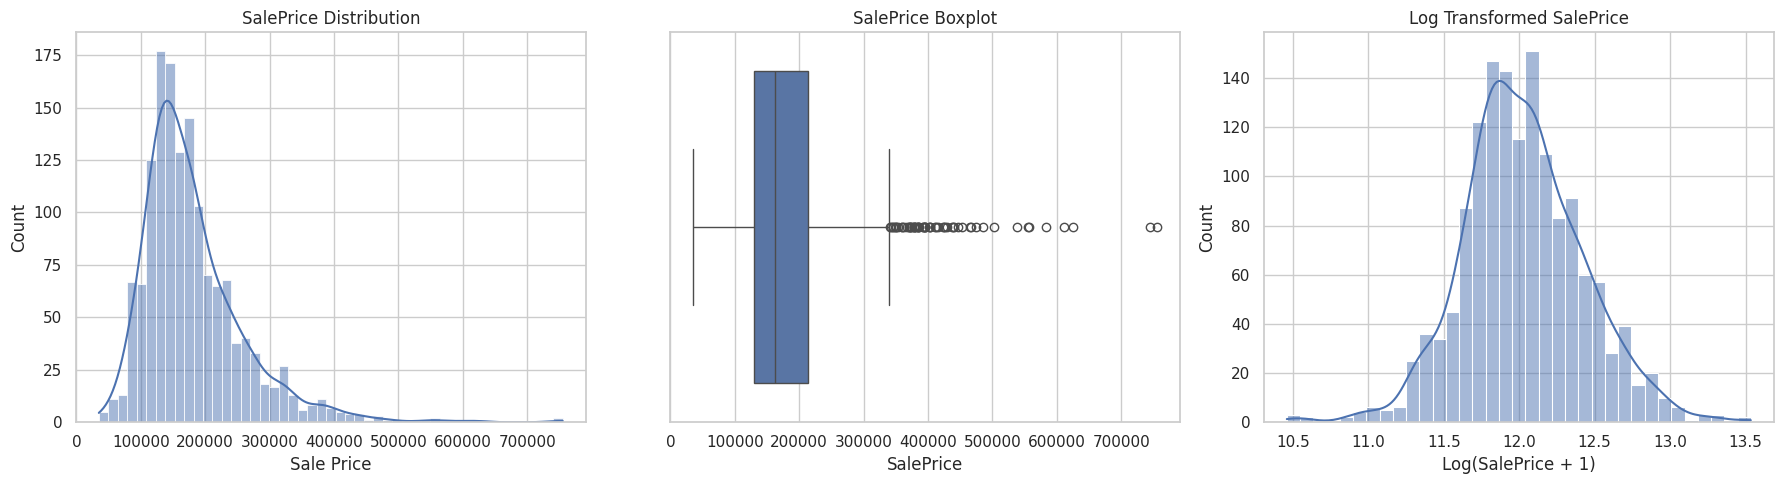

Original SalePrice Skewness: 1.8828757597682129
Log Transformed Skewness: 0.12134661989685333


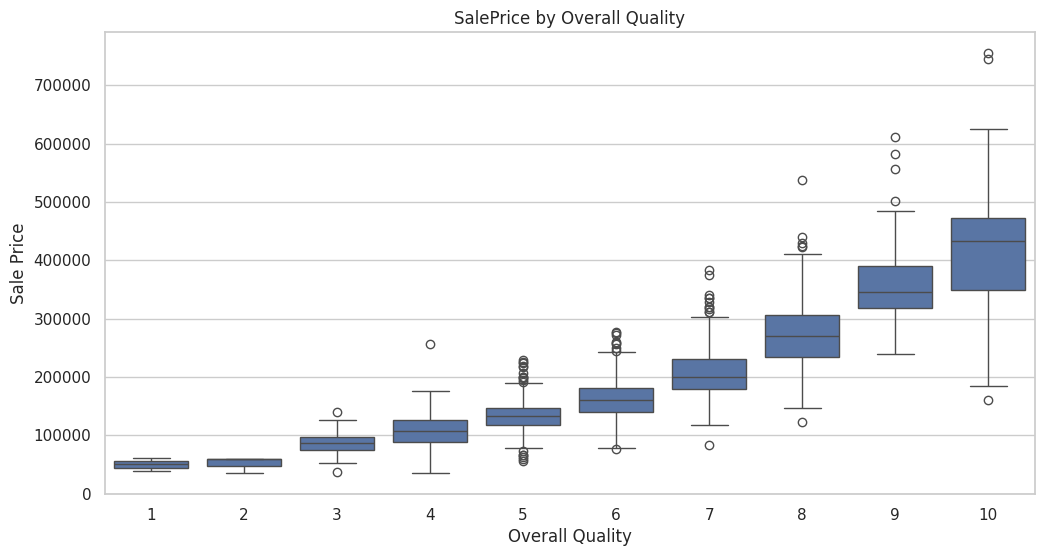

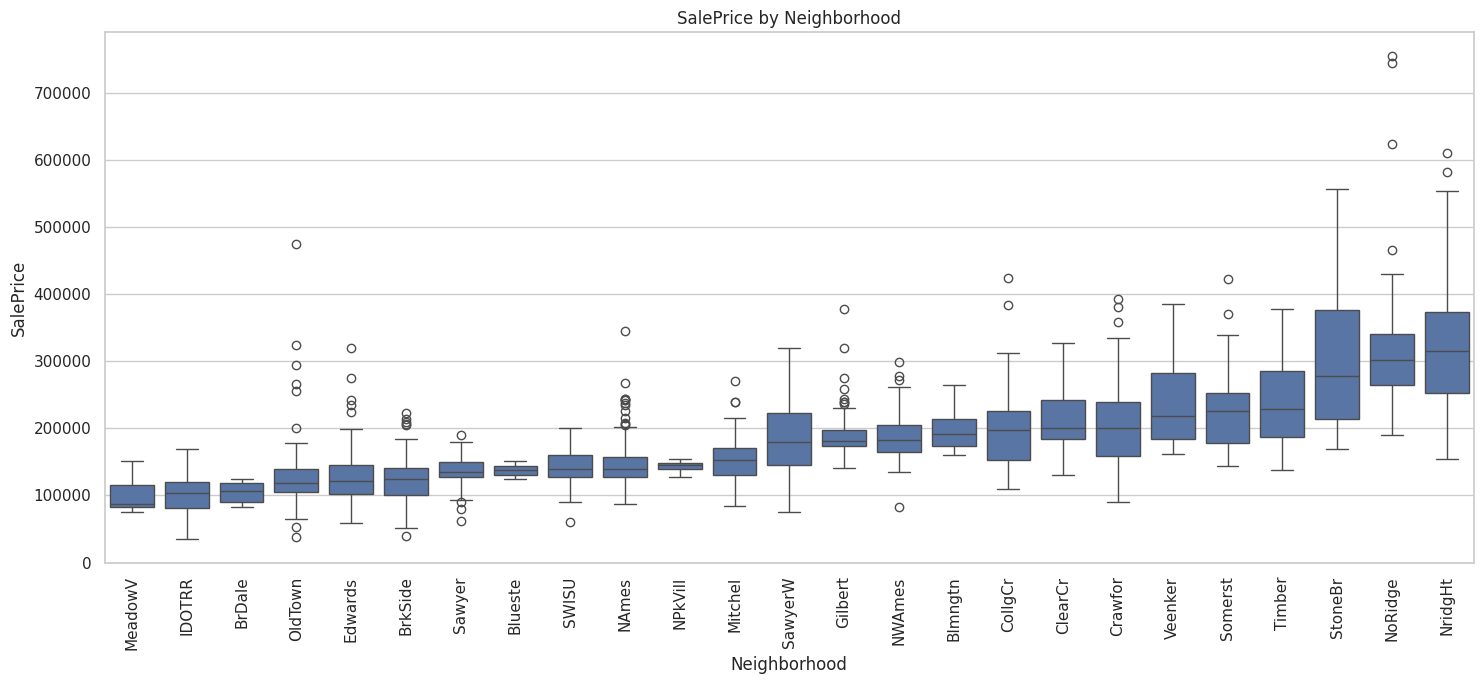

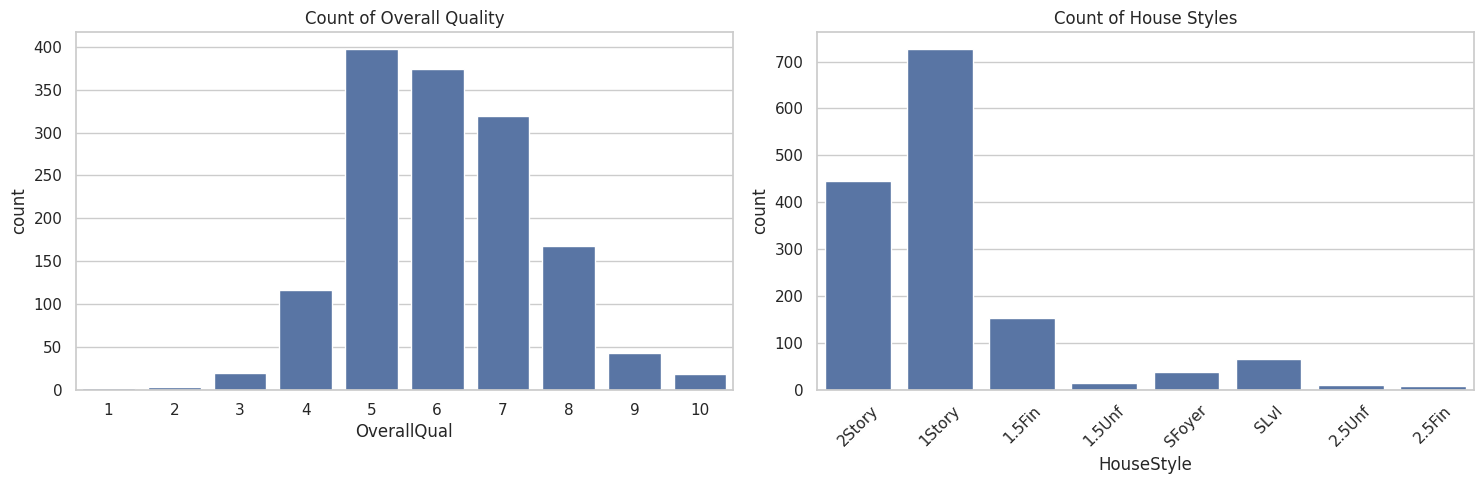

In [5]:
#Distribution Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price")

sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log Transformed SalePrice")
axes[2].set_xlabel("Log(SalePrice + 1)")

plt.tight_layout()
plt.show()

print("Original SalePrice Skewness:", df["SalePrice"].skew())
print("Log Transformed Skewness:", np.log1p(df["SalePrice"]).skew())

plt.figure(figsize=(12, 6))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(15, 7))
sns.boxplot(
    x="Neighborhood",
    y="SalePrice",
    data=df,
    order=neighborhood_order
)
plt.title("SalePrice by Neighborhood")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(x="OverallQual", data=df, ax=axes[0])
axes[0].set_title("Count of Overall Quality")

sns.countplot(x="HouseStyle", data=df, ax=axes[1])
axes[1].set_title("Count of House Styles")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#Correlation and Covariance
numeric_df = df.select_dtypes(include=np.number)

cov_matrix = numeric_df.cov()
corr_matrix = numeric_df.corr(method="pearson")

print("Covariance Matrix:")
display(cov_matrix)

print("Correlation Matrix:")
display(corr_matrix)

top_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(
    ascending=False
)

print("Top 10 Features Correlated with SalePrice:")
display(
    pd.DataFrame({
        "Feature": top_corr.head(10).index,
        "Correlation": corr_matrix.loc[top_corr.head(10).index, "SalePrice"].values
    })
)

top3 = top_corr.head(3).index

print("\nCovariance and Correlation of Top 3 Features:")

for col in top3:
    print(f"\nFeature: {col}")
    print("Covariance:", cov_matrix.loc[col, "SalePrice"])
    print("Correlation:", corr_matrix.loc[col, "SalePrice"])

print("\nCorrelation is easier to compare because its values always range from -1 to +1.")

ordinal_encoded = df[["OverallQual", "ExterQual", "KitchenQual"]].copy()

for col in ["ExterQual", "KitchenQual"]:
    ordinal_encoded[col] = ordinal_encoded[col].cat.codes

ordinal_encoded["SalePrice"] = df["SalePrice"]

print("\nSpearman Correlation for Ordinal Features:")
display(ordinal_encoded.corr(method="spearman"))

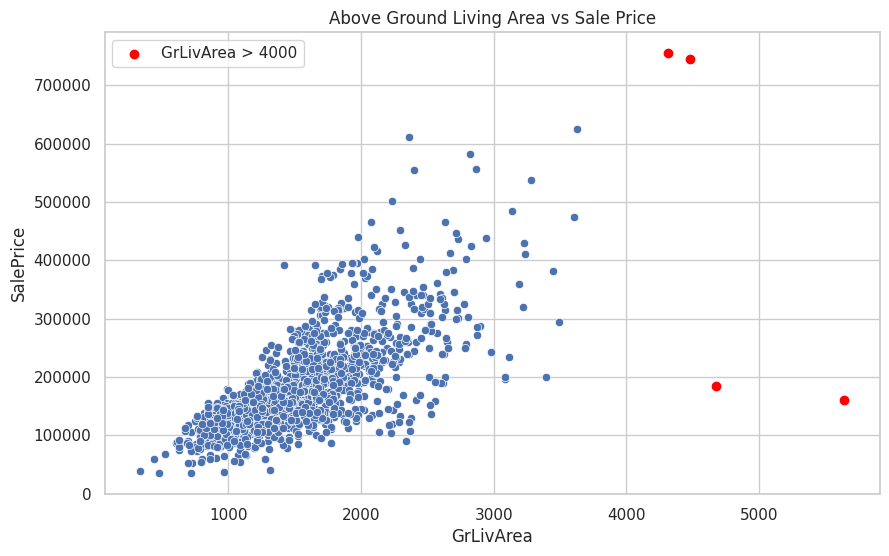

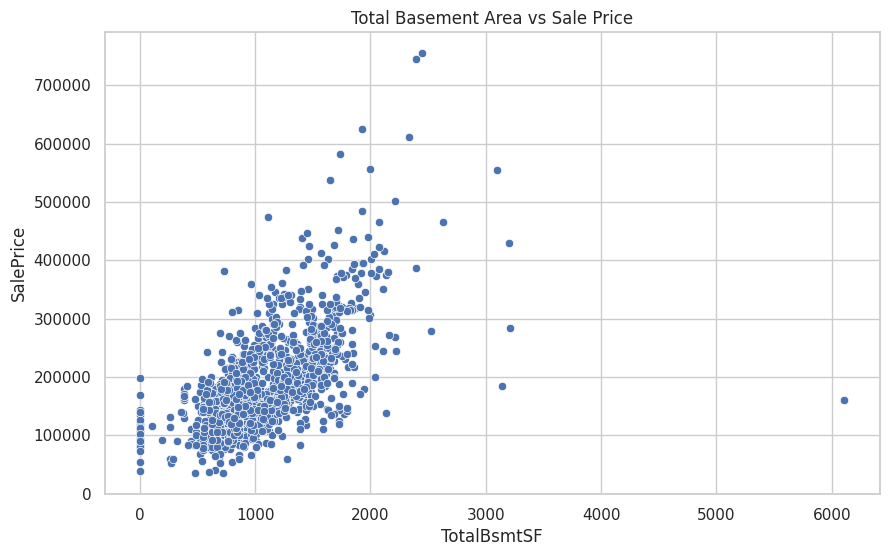

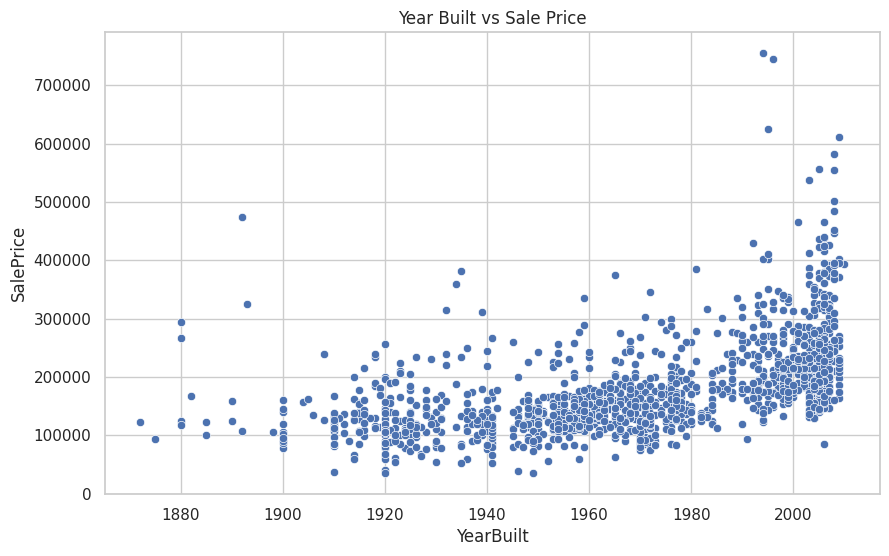

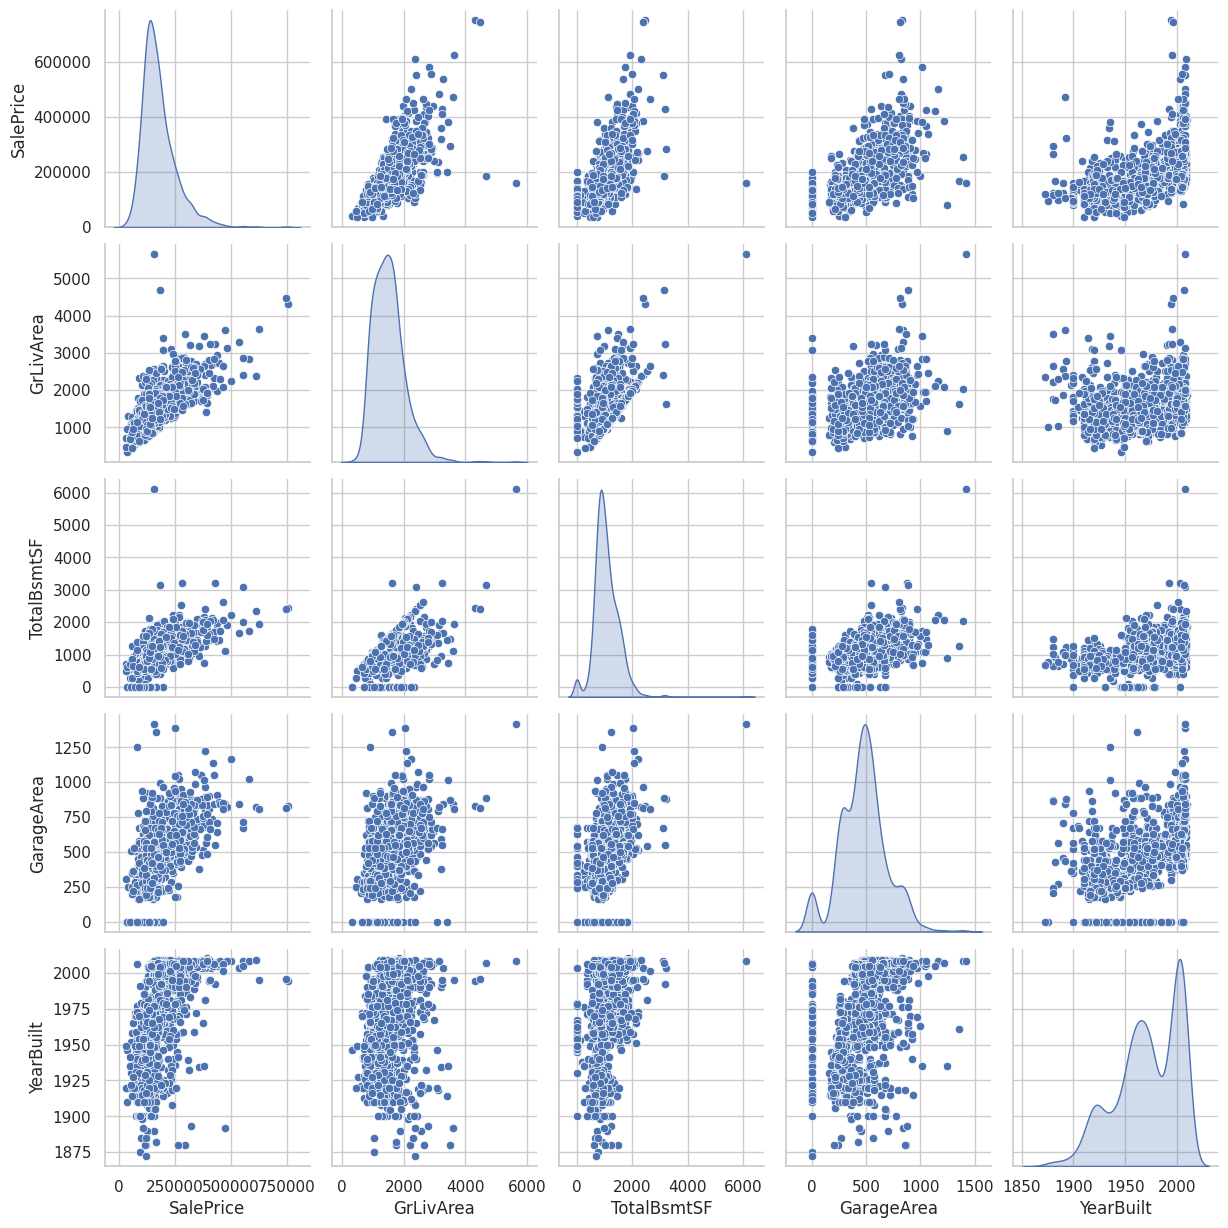

In [6]:
#Scatter Plots and Pair Plots
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="GrLivArea",
    y="SalePrice",
    data=df
)

unusual = df[df["GrLivArea"] > 4000]

plt.scatter(
    unusual["GrLivArea"],
    unusual["SalePrice"],
    color="red",
    label="GrLivArea > 4000"
)

plt.title("Above Ground Living Area vs Sale Price")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df)
plt.title("Total Basement Area vs Sale Price")
plt.xlabel("TotalBsmtSF")
plt.ylabel("SalePrice")
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x="YearBuilt", y="SalePrice", data=df)
plt.title("Year Built vs Sale Price")
plt.xlabel("YearBuilt")
plt.ylabel("SalePrice")
plt.show()

selected = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(
    df[selected].dropna(),
    diag_kind="kde"
)

plt.show()

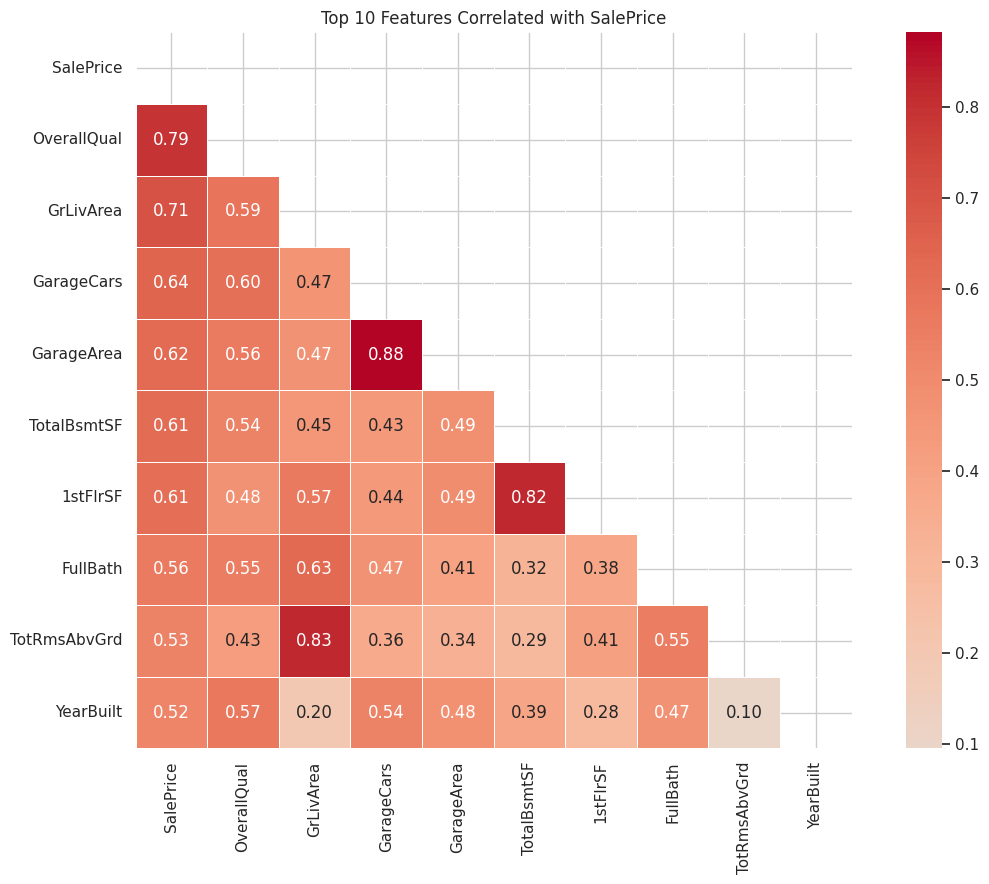

In [8]:
#Correlation Heatmap
corr_matrix = df.select_dtypes(include=np.number).corr(method="pearson")

top10_features = corr_matrix["SalePrice"].abs().sort_values(
    ascending=False
).head(10).index.tolist()

corr_top = corr_matrix.loc[top10_features, top10_features]

mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

,IQR Outliers,Z-Score Outliers,Overlap
GrLivArea,31,16,16
SalePrice,61,22,22


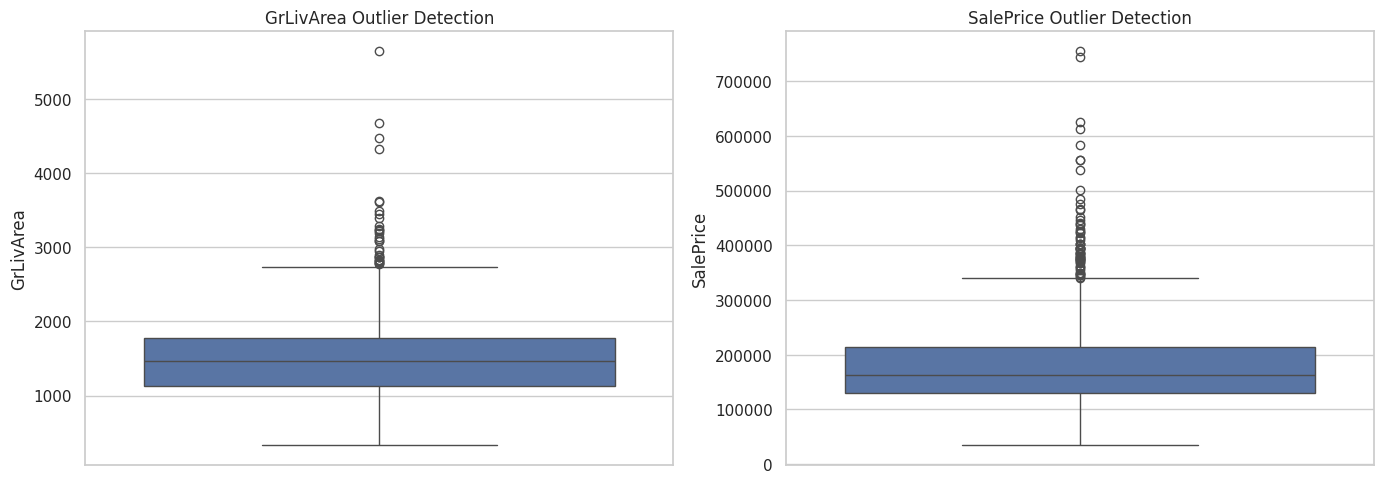

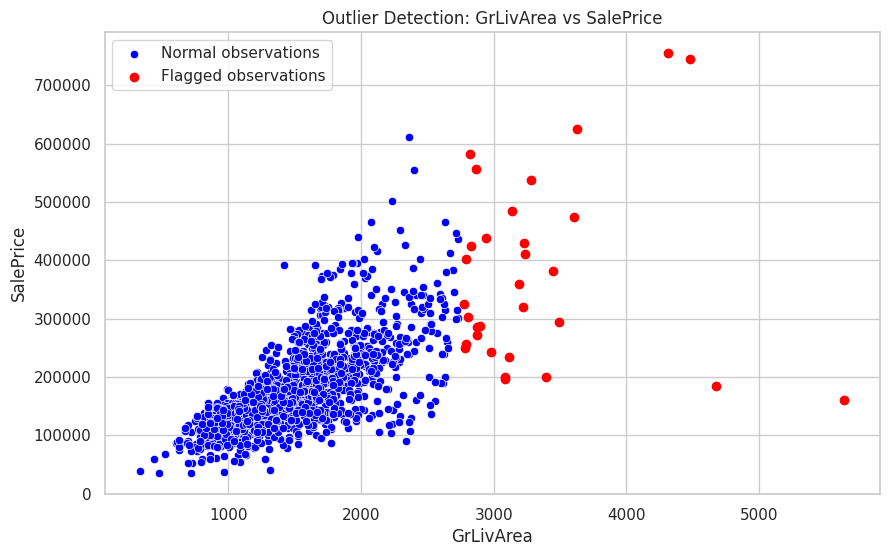

Outliers are flagged for investigation.
They are not automatically removed because unusual house sales may be genuine.
Original Dataset Shape: (1460, 81)
Dataset Shape After Review: (1460, 81)


In [9]:
#Outlier Detection
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)]


def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()

    return series[abs(z) > threshold]


outlier_results = {}

for col in ["GrLivArea", "SalePrice"]:

    iqr_result = iqr_outliers(df[col])
    zscore_result = zscore_outliers(df[col])

    iqr_indices = set(iqr_result.index)
    zscore_indices = set(zscore_result.index)

    overlap = iqr_indices.intersection(zscore_indices)

    outlier_results[col] = {
        "IQR Outliers": len(iqr_indices),
        "Z-Score Outliers": len(zscore_indices),
        "Overlap": len(overlap)
    }

display(pd.DataFrame(outlier_results).T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea Outlier Detection")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outlier Detection")

plt.tight_layout()
plt.show()

iqr_indices = set(iqr_outliers(df["GrLivArea"]).index)
zscore_indices = set(zscore_outliers(df["GrLivArea"]).index)

flagged_indices = iqr_indices.union(zscore_indices)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    color="blue",
    label="Normal observations"
)

plt.scatter(
    df.loc[list(flagged_indices), "GrLivArea"],
    df.loc[list(flagged_indices), "SalePrice"],
    color="red",
    label="Flagged observations"
)

plt.title("Outlier Detection: GrLivArea vs SalePrice")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

print("Outliers are flagged for investigation.")
print("They are not automatically removed because unusual house sales may be genuine.")

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Dataset Shape After Review:", df_clean.shape)

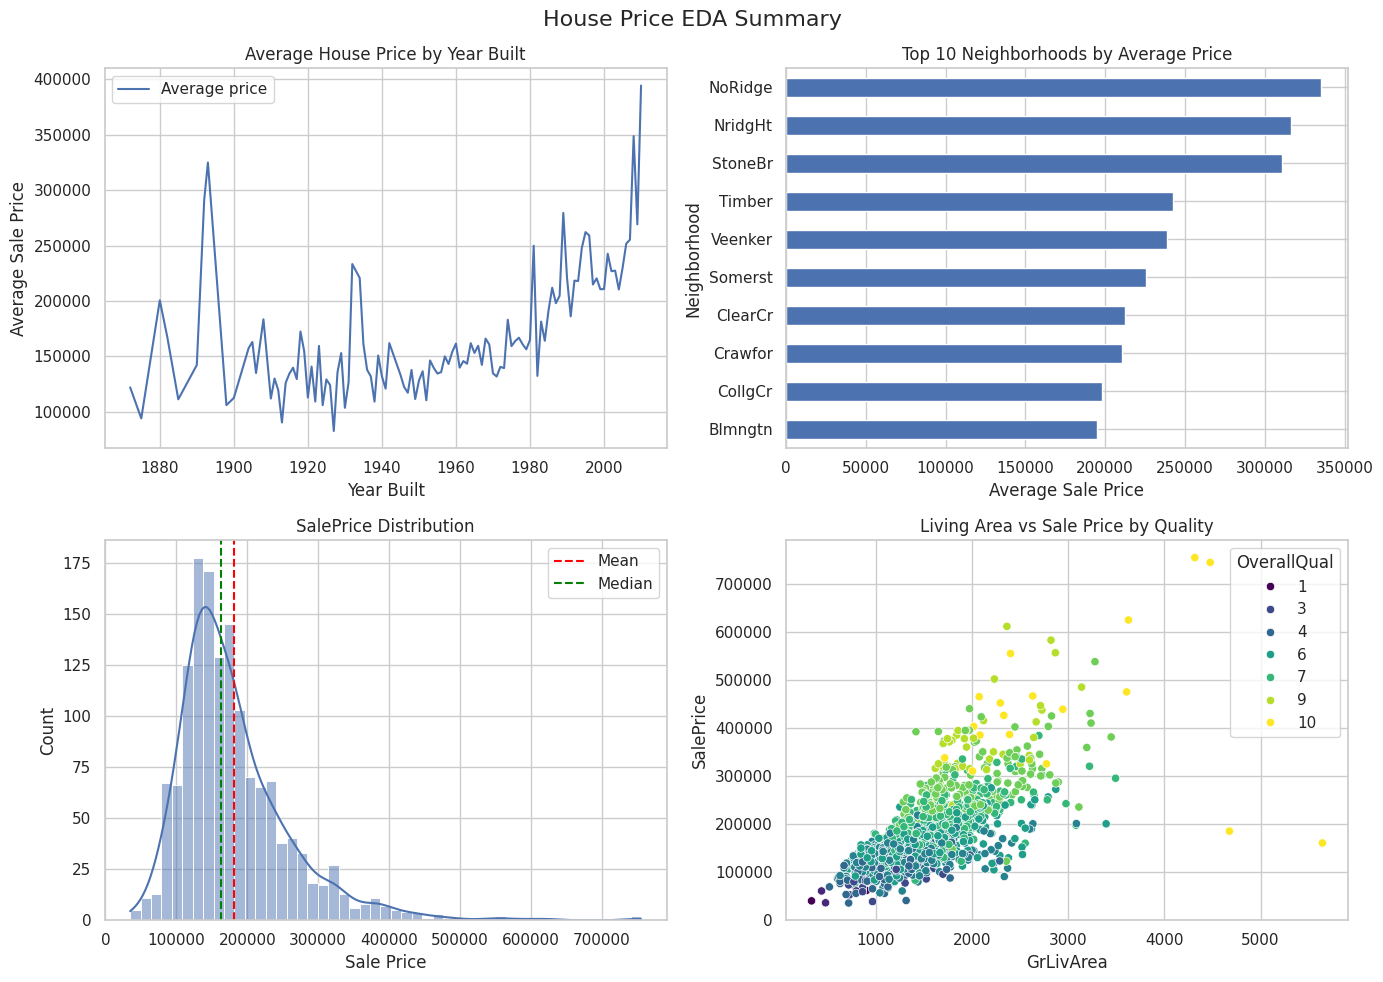

In [10]:
#Final Dashboard and Storytelling
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

yearly_prices = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    yearly_prices.index,
    yearly_prices.values,
    label="Average price"
)

axes[0, 0].set_title("Average House Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()

neighborhood_prices = df.groupby("Neighborhood")["SalePrice"].mean().nlargest(10)

neighborhood_prices.sort_values().plot(
    kind="barh",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood")

sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].axvline(
    df["SalePrice"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    df["SalePrice"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].legend()

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs Sale Price by Quality")
axes[1, 1].set_xlabel("GrLivArea")
axes[1, 1].set_ylabel("SalePrice")

plt.suptitle("House Price EDA Summary", fontsize=16)

plt.tight_layout()

plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()

In [11]:
#Final Conclusions
print("FINAL EDA CONCLUSIONS")

print("\n1. SalePrice Distribution:")
print("Mean:", df["SalePrice"].mean())
print("Median:", df["SalePrice"].median())
print("Skewness:", df["SalePrice"].skew())

print("\n2. Top 5 Features Related to SalePrice:")
display(
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(5)
)

print("\n3. Overall Quality Analysis:")
quality_prices = df.groupby("OverallQual", observed=True)["SalePrice"].median()
display(quality_prices)

print("\n4. Top 5 Neighborhoods by Median Sale Price:")
display(
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
    .head(5)
)

print("\n5. Outlier Analysis:")
print("IQR and Z-score methods were used to identify unusual observations.")
print("Outliers were retained for investigation rather than automatically removed.")

print("\n6. Missing Values:")
print("Feature absence was represented using 'None' where appropriate.")
print("Remaining numerical and categorical missing values were handled.")

print("\n7. Overall Conclusion:")
print("House prices are associated with property quality, living area,")
print("construction characteristics and neighborhood.")
print("Correlation does not establish causation.")

FINAL EDA CONCLUSIONS

1. SalePrice Distribution:
Mean: 180921.19589041095
Median: 163000.0
Skewness: 1.8828757597682129

2. Top 5 Features Related to SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581



3. Overall Quality Analysis:


,SalePrice
OverallQual,
1,50150.0
2,60000.0
3,86250.0
4,108000.0
5,133000.0
6,160000.0
7,200141.0
8,269750.0
9,345000.0



4. Top 5 Neighborhoods by Median Sale Price:


,SalePrice
Neighborhood,
NridgHt,315000.0
NoRidge,301500.0
StoneBr,278000.0
Timber,228475.0
Somerst,225500.0



5. Outlier Analysis:
IQR and Z-score methods were used to identify unusual observations.
Outliers were retained for investigation rather than automatically removed.

6. Missing Values:
Feature absence was represented using 'None' where appropriate.
Remaining numerical and categorical missing values were handled.

7. Overall Conclusion:
House prices are associated with property quality, living area,
construction characteristics and neighborhood.
Correlation does not establish causation.
